In [1]:
import numpy as np
import pandas as pd

In [2]:
pip install gensim

Note: you may need to restart the kernel to use updated packages.


In [3]:
import gensim
import os

In [4]:
import os
from nltk.tokenize import sent_tokenize
from gensim.utils import simple_preprocess
from nltk.corpus import stopwords

story = []

data_path = r"C:\Users\amank\Data Scientst\NLP\Word2Vec\dataset"

stop_words = set(stopwords.words('english'))

for filename in os.listdir(data_path):
    with open(os.path.join(data_path, filename), 'r', encoding='latin-1', errors='ignore') as f:
        corpus = f.read()
        raw_sent = sent_tokenize(corpus)

        for sent in raw_sent:
            words = simple_preprocess(sent)
            words = [word for word in words if word not in stop_words]
            story.append(words)

print(len(story))
print(story[:5])

145020
[['game', 'thrones', 'book', 'one', 'song', 'ice', 'fire', 'george', 'martin', 'prologue', 'start', 'back', 'gared', 'urged', 'woods', 'began', 'grow', 'dark', 'around'], ['wildlings', 'dead'], ['dead', 'frighten'], ['ser', 'waymar', 'royce', 'asked', 'hint', 'smile'], ['gared', 'rise', 'bait']]


In [5]:
story

[['game',
  'thrones',
  'book',
  'one',
  'song',
  'ice',
  'fire',
  'george',
  'martin',
  'prologue',
  'start',
  'back',
  'gared',
  'urged',
  'woods',
  'began',
  'grow',
  'dark',
  'around'],
 ['wildlings', 'dead'],
 ['dead', 'frighten'],
 ['ser', 'waymar', 'royce', 'asked', 'hint', 'smile'],
 ['gared', 'rise', 'bait'],
 ['old', 'man', 'past', 'fifty', 'seen', 'lordlings', 'come', 'go'],
 ['dead', 'dead', 'said'],
 ['business', 'dead'],
 ['dead'],
 ['royce', 'asked', 'softly'],
 ['proof'],
 ['saw', 'gared', 'said'],
 ['says', 'dead', 'proof', 'enough'],
 ['known', 'would', 'drag', 'quarrel', 'sooner', 'later'],
 ['wished', 'later', 'rather', 'sooner'],
 ['mother', 'told', 'dead', 'men', 'sing', 'songs', 'put'],
 ['wet', 'nurse', 'said', 'thing', 'royce', 'replied'],
 ['never', 'believe', 'anything', 'hear', 'woman', 'tit'],
 ['things', 'learned', 'even', 'dead'],
 ['voice', 'echoed', 'loud', 'twilit', 'forest'],
 ['page', 'long', 'ride', 'us', 'gared', 'pointed'],
 ['eig

In [6]:
model = gensim.models.Word2Vec(
    window = 10,
    min_count = 2
)
    

In [7]:
model.build_vocab(story)

In [8]:
model.train(story, total_examples = model.corpus_count, epochs = model.epochs)

(4396420, 4579390)

In [9]:
model.wv.most_similar('daenerys')

[('stormborn', 0.9100004434585571),
 ('unburnt', 0.8954968452453613),
 ('targaryen', 0.8566808700561523),
 ('viserys', 0.8530578017234802),
 ('dorne', 0.8405519723892212),
 ('myrcella', 0.8368685245513916),
 ('westeros', 0.820327877998352),
 ('consort', 0.8168269395828247),
 ('elia', 0.8155670762062073),
 ('glorious', 0.8127588629722595)]

In [10]:
model.wv.doesnt_match(['jon', 'rikon', 'arya', 'sansa', 'bran'])

'jon'

In [11]:
model.wv.doesnt_match(['cersei', 'jaime', 'bronn', 'tyrion'])

'bronn'

In [12]:
model.wv['jon']

array([-2.1942904 ,  0.3604859 ,  2.0230622 , -1.0975752 ,  1.6932205 ,
       -0.02728996,  0.8577777 ,  1.0514116 ,  0.54606104, -0.9232262 ,
       -0.5427575 , -2.3054683 , -0.8673364 , -0.4658973 , -0.6286699 ,
        0.20745794,  0.02141646, -0.7481897 ,  0.3872495 , -0.69598645,
        0.23776646,  0.30182797, -0.30385247,  0.15614994,  1.1545572 ,
        0.6671211 , -1.789626  ,  0.9680748 ,  1.0553887 ,  0.45696223,
       -1.5096328 ,  0.2969578 , -0.4162365 ,  0.6713861 , -1.6434942 ,
       -1.1045284 , -0.7146495 , -0.68574923,  0.9039709 , -1.8112094 ,
       -0.32515648,  0.53376144,  0.21815626, -0.11858139, -1.4973121 ,
        0.01286648,  0.70618176, -1.53938   , -1.716907  ,  2.2000325 ,
        0.85779214, -0.82971805, -0.19231716, -0.846365  ,  0.71124095,
       -0.12770434,  0.9155524 ,  1.6009421 ,  1.7231236 ,  2.3971937 ,
       -1.2571292 , -1.0376956 ,  0.44266117, -0.5759297 , -0.89584273,
        0.2253264 ,  1.7794164 ,  0.03437848, -0.24053481,  0.77

In [13]:
model.wv['jon'].shape

(100,)

In [14]:
model.wv['king']

array([-0.24742799, -0.6947236 ,  0.34501767,  1.3844428 , -1.2984048 ,
       -0.05741654,  1.0950481 , -0.423822  , -0.22071828, -0.46088555,
       -0.01096509,  0.42579362,  0.5474272 , -0.3927438 , -1.0737519 ,
        2.2188392 ,  1.7804428 ,  0.10553252, -1.0401536 , -0.72133726,
       -0.40680102,  1.6305511 , -0.1938627 , -3.898681  ,  0.9276297 ,
        1.4333612 , -1.6310631 , -0.16353275, -0.6377451 ,  1.2107483 ,
       -0.2505176 ,  2.3897667 , -0.40328208, -0.83440834, -0.48682293,
        0.02477878, -0.9666561 , -1.0854437 , -1.5880684 ,  0.20007604,
        1.1557868 , -0.39682034, -0.28193182,  1.7025211 ,  1.6176097 ,
       -1.6041884 , -0.7953565 , -0.2589471 ,  2.403386  ,  0.51594263,
       -1.8877294 , -0.9022095 ,  3.151024  , -0.61889726, -0.11950164,
        3.013045  , -2.1860054 ,  0.91705686, -0.3527558 ,  3.9258704 ,
        1.8998936 ,  0.40709937, -1.6618614 ,  1.1665647 ,  0.45900977,
       -0.80226123, -1.792891  ,  2.2934935 ,  0.42089388,  0.71

In [15]:
model.wv['king'].shape

(100,)

In [16]:
model.wv.similarity('arya', 'sansa')

np.float32(0.79724383)

In [17]:
model.wv.similarity('cersei', 'sansa')

np.float32(0.6881149)

In [18]:
model.wv.similarity('tywin', 'sansa')

np.float32(0.30203387)

In [19]:
model.wv.get_normed_vectors()

array([[-0.02515374,  0.07237499, -0.0440768 , ..., -0.11442383,
        -0.11586176,  0.20397733],
       [-0.16646808,  0.13842095,  0.05974034, ..., -0.1335665 ,
        -0.10442606,  0.21664417],
       [-0.05415476,  0.01727185, -0.02699057, ..., -0.14832108,
         0.07565004, -0.1586456 ],
       ...,
       [-0.09750406, -0.0610219 ,  0.01992504, ..., -0.04869175,
         0.09662497,  0.14448078],
       [-0.11168715,  0.02613391,  0.1499489 , ..., -0.12815791,
         0.11863829,  0.01765622],
       [-0.03205604,  0.01812116,  0.17951874, ..., -0.00237844,
         0.01244435, -0.03173239]], dtype=float32)

In [20]:
model.wv.get_normed_vectors().shape

(17310, 100)

In [21]:
y = model.wv.index_to_key

In [22]:
y

['said',
 'lord',
 'would',
 'one',
 'ser',
 'could',
 'man',
 'king',
 'men',
 'back',
 'well',
 'like',
 'jon',
 'father',
 'old',
 'hand',
 'even',
 'tyrion',
 'never',
 'know',
 'see',
 'made',
 'eyes',
 'black',
 'told',
 'lady',
 'thought',
 'time',
 'long',
 'might',
 'us',
 'come',
 'face',
 'still',
 'head',
 'red',
 'way',
 'boy',
 'page',
 'must',
 'queen',
 'good',
 'two',
 'brother',
 'night',
 'little',
 'took',
 'came',
 'though',
 'say',
 'three',
 'away',
 'dead',
 'son',
 'blood',
 'take',
 'go',
 'half',
 'make',
 'arya',
 'saw',
 'day',
 'white',
 'jaime',
 'first',
 'look',
 'want',
 'much',
 'enough',
 'sword',
 'tell',
 'girl',
 'bran',
 'great',
 'looked',
 'left',
 'knew',
 'asked',
 'gave',
 'maester',
 'called',
 'wall',
 'every',
 'heard',
 'sansa',
 'let',
 'yet',
 'went',
 'turned',
 'dany',
 'need',
 'behind',
 'around',
 'woman',
 'another',
 'snow',
 'beneath',
 'across',
 'knight',
 'keep',
 'grace',
 'found',
 'gold',
 'last',
 'cersei',
 'castle',
 '

In [23]:
from sklearn.decomposition import PCA

In [24]:
pca = PCA(n_components = 3)

In [25]:
X = pca.fit_transform(model.wv.get_normed_vectors())

In [26]:
X[:5]

array([[ 0.49414134,  0.03789091,  0.23000261],
       [ 0.4075532 ,  0.5314098 ,  0.43112788],
       [ 0.55386156, -0.02005182, -0.30086398],
       [ 0.01212385,  0.16740459,  0.00836352],
       [ 0.27277708,  0.48175544,  0.57058406]], dtype=float32)

In [27]:
X.shape

(17310, 3)

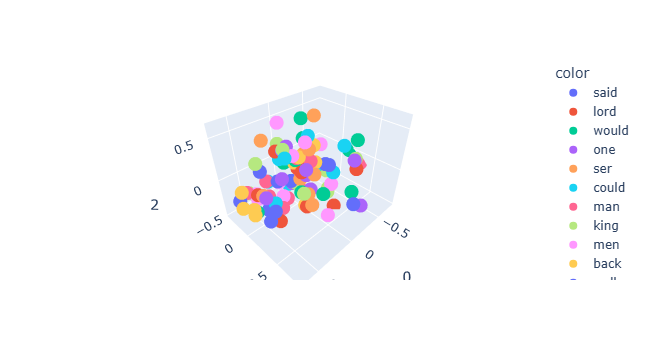

In [30]:
# plotting frequent 100 words
import plotly.express as px
fig = px.scatter_3d(X[:100], x=0, y=1, z=2, color=y[:100])
fig.show()